In [8]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Same seed => same simulated results every run
rng = np.random.default_rng(42)
plt.style.use("seaborn-v0_8-whitegrid")

<h1 face="Times New Roma" color="#3f134f">Important Probability Theorems</h1>

<p>
  <a href="https://github.com/daodavid">author: daodeiv (David Stankov)</a>
</p>

<h6>
  <font size="4" face="Times New Roma" color="#3f134f">
    <ul style="margin-left: 30px">
      <li><a href="#lln">Law of Large Numbers</a></li><br>
      <li><a href="#clt">Central Limit Theorem</a></li><br>
      <li><a href="#zscore">Z-score</a></li><br>
      <li><a href="#sampling">Sampling distributions</a></li><br>
    </ul>
  </font>
</h6>


<h2 id="lln" face="Times New Roma" color="#270336">1. Law of Large Numbers (LLN)</h2>

<h3>1.1 Definition</h3>

The Law of Large Numbers says that as the number of independent observations increases, the sample average tends to get closer to the true population expected value.

In simple words: the more times we repeat an experiment, the closer the average result gets to the expected value.


<h3>1.2 Formula</h3>

$$
\bar{X}_n = \frac{X_1 + X_2 + \cdots + X_n}{n}
$$


As the sample size increases:

$$
\bar{X}_n \longrightarrow \mu
$$


where

- $\bar{X}_n$ = sample mean
- $X_i$ = individual observation
- $n$ = number of observations
- $\mu$ = population mean (expected value)


<h3>1.3 Example: tossing a coin</h3>

Imagine a fair coin: $P(H)=0.5$ and $P(T)=0.5$.

If you toss it only $10$ times, you might get $7$ heads. The proportion is

$$
\frac{7}{10} = 0.7
$$


If you toss it $10{,}000$ times, the proportion will generally get closer to $0.5$.


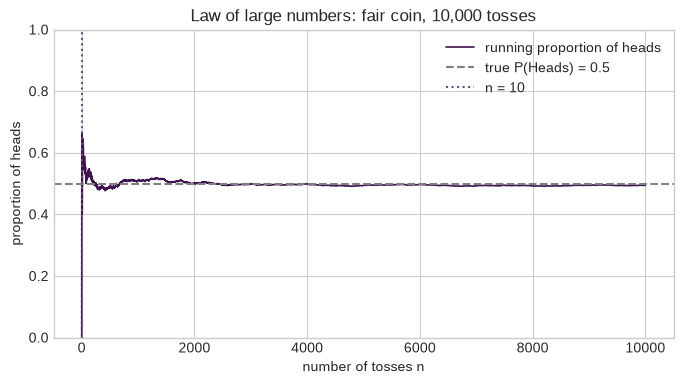

after     10 tosses: 0.400
after 10,000 tosses: 0.494


In [9]:
n = 10_000
heads = rng.integers(0, 2, size=n)  # 1 = heads, 0 = tails
proportion = np.cumsum(heads) / np.arange(1, n + 1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(proportion, color="#3f134f", lw=1.2, label="running proportion of heads")
ax.axhline(0.5, color="gray", ls="--", label="true P(Heads) = 0.5")
ax.axvline(10, color="#6b4c7a", ls=":", label="n = 10")
ax.set_xlabel("number of tosses n")
ax.set_ylabel("proportion of heads")
ax.set_title("Law of large numbers: fair coin, 10,000 tosses")
ax.set_ylim(0, 1)
ax.legend()
plt.show()

print(f"after     10 tosses: {proportion[9]:.3f}")
print(f"after 10,000 tosses: {proportion[-1]:.3f}")

<h3>1.4 Weak and strong laws</h3>

1. **Weak law:** the sample mean converges to the population mean *in probability*.
2. **Strong law:** the sample mean converges to the population mean *almost surely*.

For an introductory course, the basic idea and the weak law are enough.


<h2 id="clt" face="Times New Roma" color="#270336">2. Central Limit Theorem (CLT)</h2>


<h3>2.1 Definition</h3>

The CLT is one of the main reasons the normal (bell) curve appears so often in statistics.

If we take sufficiently large random samples from a population with a **finite mean and variance**, the distribution of the sample mean becomes approximately normal, **regardless of the original population distribution**.

In simple words: even if the original data are not normal, averages of many large samples tend to look normal.

<h3>2.2 The idea</h3>

Start from a skewed population. Repeatedly take random samples and compute each sample's average.


For example, five sample averages might be $45$, $52$, $48$, $50$, and $47$. If we repeat this thousands of times, the histogram of those averages looks approximately like a bell curve.


Below, the population is **exponential** with mean $\mu=50$ (skewed, not a bell curve). We draw $5{,}000$ samples of size $n$ and plot the histogram of the sample means $\bar{X}_n$.


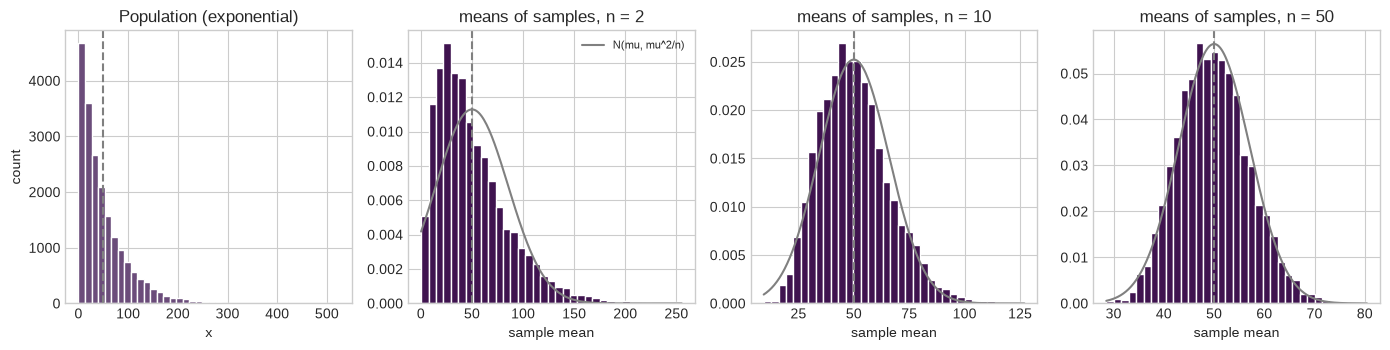

five example sample means (n=40): [47.6 51.6 51.2 57.6 48.1]


In [10]:
mu = 50.0
n_samples = 5_000
sample_sizes = [2, 10, 50]

population = rng.exponential(scale=mu, size=20_000)

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))

axes[0].hist(population, bins=40, color="#6b4c7a", edgecolor="white")
axes[0].axvline(mu, color="gray", ls="--")
axes[0].set_title("Population (exponential)")
axes[0].set_xlabel("x")
axes[0].set_ylabel("count")

for ax, n in zip(axes[1:], sample_sizes):
    draws = rng.exponential(scale=mu, size=(n_samples, n))
    means = draws.mean(axis=1)
    ax.hist(means, bins=35, density=True, color="#3f134f", edgecolor="white")
    x = np.linspace(means.min(), means.max(), 200)
    se = mu / np.sqrt(n)  # for Exp(mean=mu), Var = mu^2
    pdf = np.exp(-0.5 * ((x - mu) / se) ** 2) / (se * np.sqrt(2 * np.pi))
    ax.plot(x, pdf, color="gray", lw=1.5, label="N(mu, mu^2/n)")
    ax.axvline(mu, color="gray", ls="--")
    ax.set_title(f"means of samples, n = {n}")
    ax.set_xlabel("sample mean")

axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

example = rng.exponential(scale=mu, size=(5, 40)).mean(axis=1)
print("five example sample means (n=40):", np.round(example, 1))

<h3>2.3 Formulas</h3>

The sampling distribution of the sample mean has

$$
\mu_{\bar{X}} = \mu, \qquad
\sigma_{\bar{X}} = \frac{\sigma}{\sqrt{n}}
$$

and the standardized score

$$
Z = \frac{\bar{X} - \mu}{\sigma / \sqrt{n}}
$$

| Symbol | Meaning |
|--------|---------|
| $\bar{X}$ | sample mean |
| $\mu$ | population mean |
| $\sigma$ | population standard deviation |
| $n$ | sample size |
| $\sigma/\sqrt{n}$ | standard error |
| $Z$ | standard normal score |


<h3>2.4 Standard error</h3>

The **standard error** (SE) measures how much sample means typically vary from one sample to another:

$$
\mathrm{SE} = \frac{\sigma}{\sqrt{n}}
$$

- larger $n$ $\Rightarrow$ smaller SE (means concentrate around $\mu$)
- smaller $n$ $\Rightarrow$ larger SE

**Example.** $\mu=100$, $\sigma=20$, $n=100$:

$$
\mathrm{SE} = \frac{20}{\sqrt{100}} = 2
$$


Compare different sample sizes when $\sigma=20$:

| Sample size $n$ | Standard error $\sigma/\sqrt{n}$ |
|-----------------|-----------------------------------|
| 25 | 4 |
| 100 | 2 |
| 400 | 1 |
| 1,600 | 0.5 |


<h3>2.5 Conditions for the CLT</h3>

1. The sample is randomly selected.
2. Observations are independent (or approximately independent).
3. The population has a finite mean and a finite variance.
4. If the population is not normal, $n$ should be large enough.

Exam note: $n \ge 30$ is a common rule of thumb, not a guarantee. Highly skewed or heavy-tailed populations may need a larger $n$.

If the population itself is normal, $\bar{X}$ is normal for any sample size (independent observations).


<h3>2.6 Solved exercise</h3>

A population has $\mu=50$, $\sigma=10$, and we take $n=100$. What is $P(\bar{X} > 52)$?

**Step 1.** Standard error:

$$
\mathrm{SE} = \frac{10}{\sqrt{100}} = 1
$$

**Step 2.** Z-score:

$$
Z = \frac{\bar{X}-\mu}{\mathrm{SE}} = \frac{52-50}{1} = 2
$$

**Step 3.** Probability:

$$
P(\bar{X} > 52) = P(Z > 2) = 1 - P(Z < 2) = 1 - 0.9772 = 0.0228
$$

There is about a $2.28\%$ chance that the sample mean is greater than $52$.


<h3 id="zscore">2.7 Understand the Z-score visually</h3>


The left plot is the sampling distribution of $\bar{X}$ ($\mu=50$, $\mathrm{SE}=1$). The right plot is the same picture on the $Z$ scale. The shaded tail is $P(\bar{X} > 52) = P(Z > 2)$.


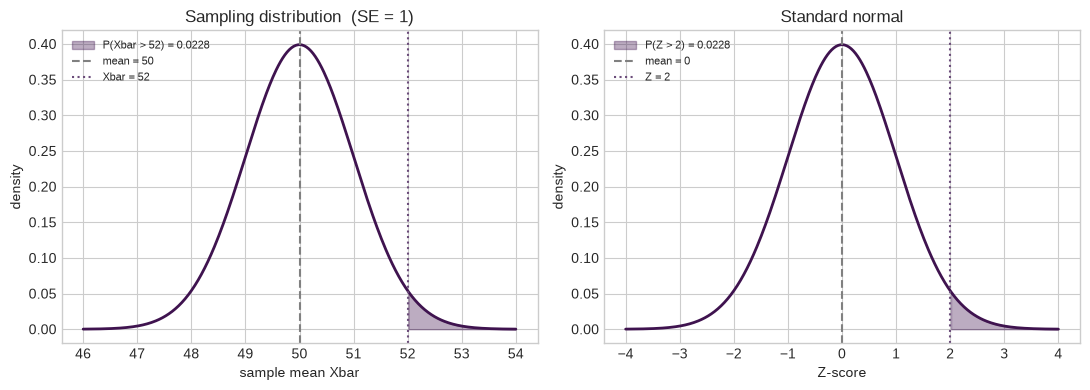

SE = 1
Z  = (52 - 50) / 1 = 2
P(Xbar > 52) = P(Z > 2) = 0.0228


In [11]:
from scipy.stats import norm

mu, sigma, n = 50.0, 10.0, 100
se = sigma / np.sqrt(n)  # 1.0
x_cut = 52.0
z_cut = (x_cut - mu) / se  # 2.0
p_tail = 1 - norm.cdf(z_cut)

x = np.linspace(mu - 4 * se, mu + 4 * se, 400)
pdf_x = norm.pdf(x, loc=mu, scale=se)
z = np.linspace(-4, 4, 400)
pdf_z = norm.pdf(z)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(x, pdf_x, color="#3f134f", lw=2)
axes[0].fill_between(x, pdf_x, where=(x >= x_cut), color="#3f134f", alpha=0.35,
                     label=f"P(Xbar > {x_cut:g}) = {p_tail:.4f}")
axes[0].axvline(mu, color="gray", ls="--", label=f"mean = {mu:g}")
axes[0].axvline(x_cut, color="#6b4c7a", ls=":", label=f"Xbar = {x_cut:g}")
axes[0].set_xlabel("sample mean Xbar")
axes[0].set_ylabel("density")
axes[0].set_title(f"Sampling distribution  (SE = {se:g})")
axes[0].legend(fontsize=8)

axes[1].plot(z, pdf_z, color="#3f134f", lw=2)
axes[1].fill_between(z, pdf_z, where=(z >= z_cut), color="#3f134f", alpha=0.35,
                     label=f"P(Z > {z_cut:g}) = {p_tail:.4f}")
axes[1].axvline(0, color="gray", ls="--", label="mean = 0")
axes[1].axvline(z_cut, color="#6b4c7a", ls=":", label=f"Z = {z_cut:g}")
axes[1].set_xlabel("Z-score")
axes[1].set_ylabel("density")
axes[1].set_title("Standard normal")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

print(f"SE = {se:g}")
print(f"Z  = ({x_cut:g} - {mu:g}) / {se:g} = {z_cut:g}")
print(f"P(Xbar > {x_cut:g}) = P(Z > {z_cut:g}) = {p_tail:.4f}")

A **Z-score** (standard score) says how many standard errors a sample mean sits from the population mean:

$$
Z = \frac{\bar{X} - \mu}{\sigma / \sqrt{n}}
$$

It describes **relative unusualness**, not the raw units of $X$:

- $Z=0$: the sample mean equals $\mu$
- $Z>0$: the sample mean is above $\mu$; $Z<0$ means it is below
- $|Z|$ is the distance from $\mu$ in units of the standard error $\sigma/\sqrt{n}$

In the figure, $\bar{X}=52$ is $2$ standard errors above $50$, so $Z=2$. Under the CLT, $Z$ is approximately standard normal $N(0,1)$. That is why the shaded tails on the two plots have the same area: $P(\bar{X}>52)=P(Z>2)\approx 0.0228$. A large $|Z|$ means that sample mean would be rare if $\mu$ were the true mean.


<h2 id="sampling" face="Times New Roma" color="#270336">3. Sampling distributions</h2>


This section connects the Law of Large Numbers and the Central Limit Theorem to everyday sampling.

<h3>3.1 What is a sampling distribution?</h3>

A **sampling distribution** is the probability distribution of a statistic computed from samples of the same size drawn from a population.

In simple words: take many samples, compute the average of each, and collect those averages. That collection is the sampling distribution of the sample mean.

**Example.** A university has $1{,}000$ students. Instead of asking every student their age, you repeatedly:

1. randomly select $50$ students
2. compute their mean age
3. repeat many times

Those mean ages form a sampling distribution.


In [12]:
# Population: 1,000 student ages (mostly 18-25, a few older students).
young = rng.integers(18, 26, size=900)
older = rng.integers(26, 46, size=100)
ages = np.concatenate([young, older])
rng.shuffle(ages)

N, n, n_samples = len(ages), 50, 2_000
mu = ages.mean()
sigma = ages.std(ddof=0)
se = sigma / np.sqrt(n)

sample_means = np.array([
    rng.choice(ages, size=n, replace=False).mean()
    for _ in range(n_samples)
])
five_means = sample_means[:5]

examples = pd.DataFrame({
    "sample": np.arange(1, 6),
    "mean age": np.round(five_means, 2),
})
display(examples)

summary = pd.DataFrame({
    "quantity": ["population mean mu", "mean of sample means", "population SD sigma", "SE = sigma/sqrt(n)", "SD of sample means"],
    "value": [mu, sample_means.mean(), sigma, se, sample_means.std(ddof=0)],
})
display(summary.round(3))

,sample,mean age
0,1,22.80
1,2,22.14
2,3,23.02
3,4,22.58
4,5,22.56


,quantity,value
0,population mean mu,22.897
1,mean of sample means,22.869
2,population SD sigma,5.137
3,SE = sigma/sqrt(n),0.726
4,SD of sample means,0.675


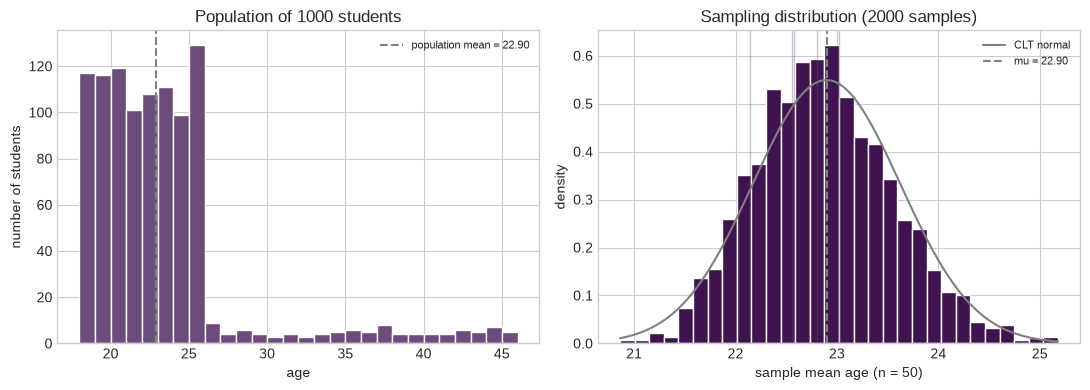

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(ages, bins=range(18, 47), color="#6b4c7a", edgecolor="white")
axes[0].axvline(mu, color="gray", ls="--", label=f"population mean = {mu:.2f}")
axes[0].set_xlabel("age")
axes[0].set_ylabel("number of students")
axes[0].set_title(f"Population of {N} students")
axes[0].legend(fontsize=8)

axes[1].hist(sample_means, bins=30, density=True, color="#3f134f", edgecolor="white")
x = np.linspace(sample_means.min(), sample_means.max(), 200)
pdf = np.exp(-0.5 * ((x - mu) / se) ** 2) / (se * np.sqrt(2 * np.pi))
axes[1].plot(x, pdf, color="gray", lw=1.5, label="CLT normal")
axes[1].axvline(mu, color="gray", ls="--", label=f"mu = {mu:.2f}")
for m in five_means:
    axes[1].axvline(m, color="#6b4c7a", alpha=0.35, lw=1)
axes[1].set_xlabel("sample mean age (n = 50)")
axes[1].set_ylabel("density")
axes[1].set_title(f"Sampling distribution ({n_samples} samples)")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

Interview students one by one. The running sample mean $\bar{X}_n$ moves toward the true population mean $\mu$ as $n$ grows (law of large numbers).


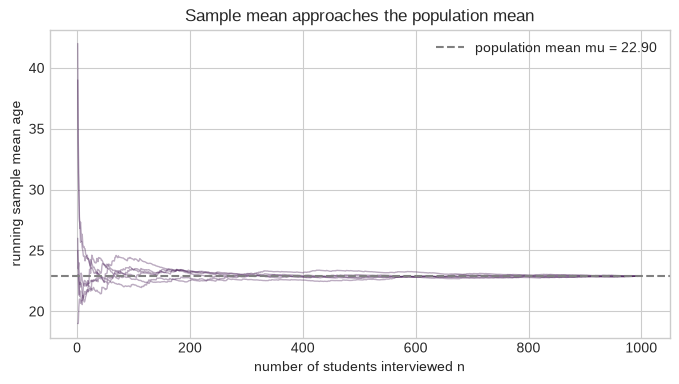

In [14]:
n_paths = 6
k = np.arange(1, N + 1)

fig, ax = plt.subplots(figsize=(8, 4))
for i in range(n_paths):
    order = rng.permutation(ages)
    running_mean = np.cumsum(order) / k
    ax.plot(k, running_mean, color="#3f134f", alpha=0.35, lw=1)

ax.axhline(mu, color="gray", ls="--", label=f"population mean mu = {mu:.2f}")
ax.set_xlabel("number of students interviewed n")
ax.set_ylabel("running sample mean age")
ax.set_title("Sample mean approaches the population mean")
ax.legend()
plt.show()

<h3>3.2 Sampling distribution of the sample mean</h3>

This is the most important sampling distribution. The sample mean is

$$
\bar{X} = \frac{1}{n}\sum_{i=1}^{n} X_i
$$

Its sampling distribution has

$$
\mu_{\bar{X}} = \mu, \qquad
\sigma^{2}_{\bar{X}} = \frac{\sigma^{2}}{n}, \qquad
\sigma_{\bar{X}} = \frac{\sigma}{\sqrt{n}}
$$

- $\mu$ = population mean
- $\sigma^{2}$ = population variance
- $\sigma$ = population standard deviation
- $n$ = sample size


<h3>3.3 Sampling distribution of the sample proportion</h3>

Use this when the outcome is a category (pass/fail, prefer a product, support a decision).

$$
\hat{p} = \frac{x}{n}
$$

- $\hat{p}$ = sample proportion
- $x$ = number of successes
- $n$ = sample size
- $p$ = true population proportion

$$
\mu_{\hat{p}} = p, \qquad
\mathrm{SE}_{\hat{p}} = \sqrt{\frac{p(1-p)}{n}}
$$

A normal approximation is usually used when $np \ge 10$ and $n(1-p) \ge 10$ (some courses use $5$ instead of $10$).


<h3>3.4 Example: sampling distribution of the mean</h3>

A population has $\mu=80$, $\sigma=12$, $n=36$. Find the mean and standard error of $\bar{X}$.

$$
\mu_{\bar{X}} = \mu = 80
$$

$$
\mathrm{SE} = \frac{\sigma}{\sqrt{n}} = \frac{12}{\sqrt{36}} = 2
$$

If we repeatedly take samples of $36$ observations, their averages have mean $80$ and standard deviation $2$.


<h3>3.5 Example: sampling distribution of the proportion</h3>

In a university, $60\%$ of students pass an exam. We randomly select $n=100$ students.

$$
p = 0.60, \qquad \mu_{\hat{p}} = p = 0.60
$$

$$
\mathrm{SE}_{\hat{p}} = \sqrt{\frac{0.60 \cdot 0.40}{100}} = \sqrt{0.0024} \approx 0.049
$$


<h3>3.6 Sampling distribution vs CLT</h3>

| Sampling distribution | Central Limit Theorem |
|-----------------------|------------------------|
| Describes the distribution of a statistic | Explains why some sampling distributions become approximately normal |
| Can describe means, proportions, etc. | Gives a normal approximation under suitable conditions |
| Exists for a given sampling procedure | Is a theorem about that distribution's shape |

A sampling distribution is the object we study. The CLT is a tool to approximate it.

<h3>3.7 Mean vs proportion (exam formulas)</h3>

| Feature | Sample mean | Sample proportion |
|---------|-------------|-------------------|
| Symbol | $\bar{X}$ | $\hat{p}$ |
| Population parameter | $\mu$ | $p$ |
| Expected value | $\mu$ | $p$ |
| Standard error | $\sigma/\sqrt{n}$ | $\sqrt{p(1-p)/n}$ |
| Used for | numerical data | categories / percentages |
